# 02 · Kết quả mô hình và hệ thống

Notebook này gom các kết quả đánh giá của đề tài vào một chỗ. Số liệu được đọc từ các file trong
`models/vehicle_yolo26/`, mỗi file do một script sinh ra. Khi chạy lại script thì chạy lại notebook là số liệu cập nhật.

| File | Script | Nội dung |
| --- | --- | --- |
| `eval_test.json` | `scripts/evaluate.py` | P, R, mAP trên tập test, FPS pipeline |
| `results.csv` | `scripts/train.py` | chỉ số theo từng epoch |
| `split_compare.json` | `scripts/compare_splits.py` | so sánh train, valid, test |
| `leakage_check.json` | `scripts/check_leakage.py` | ảnh trùng giữa các tập |
| `baseline_compare.json` | `scripts/compare_baseline.py` | fine-tune so với COCO pretrained |
| `map_analysis.json` | `scripts/analyze_map.py` | AP theo ngưỡng IoU |
| `tracker_compare.json` | `scripts/compare_trackers.py` | ByteTrack và BoT-SORT |
| `count_check.json` | `scripts/check_count.py` | số xe hệ thống đếm so với đếm tay |
| `benchmark.json`, `latency.json` | `scripts/benchmark.py`, `scripts/measure_latency.py` | tốc độ, độ trễ |

In [1]:
%matplotlib inline
import sys
from pathlib import Path

# Notebook co the mo tu thu muc goc hoac tu notebooks/
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
for p in (ROOT / "src", ROOT / "scripts"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

import json

import matplotlib.pyplot as plt
import pandas as pd

from traffic.classes import CLASS_COLORS_HEX, CLASS_LABELS_VI, CLASS_NAMES

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
RUN = ROOT / "models" / "vehicle_yolo26"
VI = [CLASS_LABELS_VI[c] for c in CLASS_NAMES]
COLORS = [CLASS_COLORS_HEX[c] for c in CLASS_NAMES]


def J(name):
    """Doc mot file ket qua JSON trong models/vehicle_yolo26/."""
    return json.loads((RUN / f"{name}.json").read_text(encoding="utf-8"))


def per_class_df(d, keys=("precision", "recall", "mAP50", "mAP50_95")):
    return pd.DataFrame({CLASS_LABELS_VI[c]: {k: d["per_class"][c][k] for k in keys if k in d["per_class"][c]}
                         for c in CLASS_NAMES}).T


ev = J("eval_test")

## 1. Kết quả trên tập test theo lớp

Tat ca: P = 0.871, R = 0.867, mAP50 = 0.928, mAP50-95 = 0.614


,precision,recall,mAP50,mAP50_95
Xe con,0.887,0.894,0.946,0.710
Xe tải,0.871,0.894,0.954,0.701
Xe máy,0.855,0.812,0.884,0.432


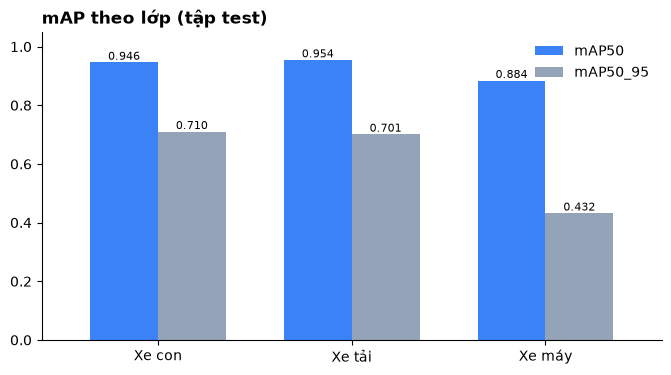

In [2]:
print(f"Tat ca: P = {ev['precision']:.3f}, R = {ev['recall']:.3f}, "
      f"mAP50 = {ev['mAP50']:.3f}, mAP50-95 = {ev['mAP50_95']:.3f}")
df_cls = per_class_df(ev)
display(df_cls.round(3))

ax = df_cls[["mAP50", "mAP50_95"]].plot.bar(rot=0, figsize=(8, 4), color=["#3B82F6", "#94A3B8"], width=0.7)
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=8)
ax.set_ylim(0, 1.05); ax.legend(frameon=False); ax.set_title("mAP theo lớp (tập test)", loc="left", weight="bold")
plt.show()

mAP@0.5 tính một box là đúng khi nó trùng với box thật từ 50% trở lên. Với bài toán đếm thì mức này là đủ, vì chỉ cần
tìm ra xe và nhận đúng loại xe. mAP@0.5:0.95 lấy trung bình ở các ngưỡng từ 0.5 đến 0.95, nên box phải vẽ khít hơn mới
được điểm cao. Xe máy là lớp có hai cột chênh nhau nhiều nhất, mục 4 sẽ xem lý do.

## 2. Quá trình huấn luyện

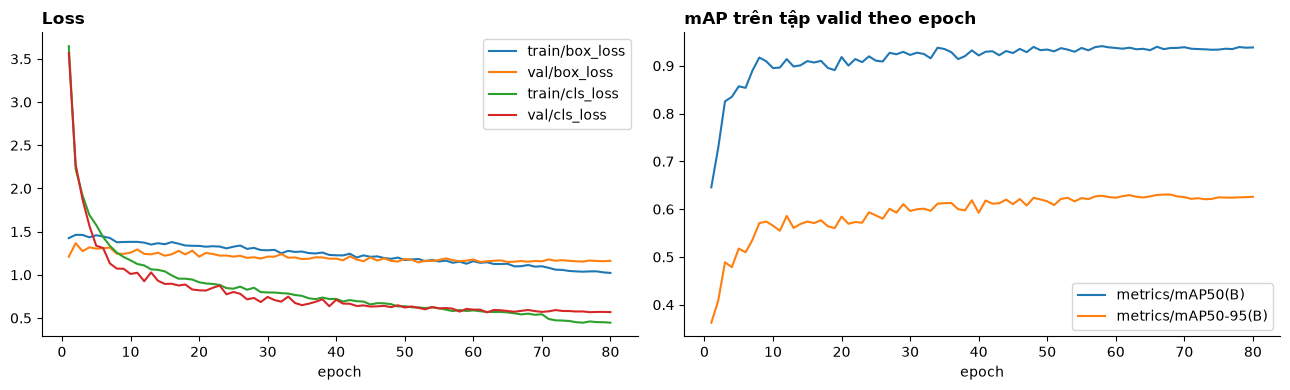

So epoch: 80 | epoch tot nhat (theo mAP50-95 valid): 67 | mAP50 = 0.935, mAP50-95 = 0.631


In [3]:
res = pd.read_csv(RUN / "results.csv")
res.columns = res.columns.str.strip()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
res.plot(x="epoch", y=["train/box_loss", "val/box_loss", "train/cls_loss", "val/cls_loss"], ax=axes[0])
axes[0].set_title("Loss", loc="left", weight="bold")
res.plot(x="epoch", y=["metrics/mAP50(B)", "metrics/mAP50-95(B)"], ax=axes[1])
axes[1].set_title("mAP trên tập valid theo epoch", loc="left", weight="bold")
plt.tight_layout(); plt.show()

best = res.loc[res["metrics/mAP50-95(B)"].idxmax()]
print(f"So epoch: {len(res)} | epoch tot nhat (theo mAP50-95 valid): {int(best.epoch)} "
      f"| mAP50 = {best['metrics/mAP50(B)']:.3f}, mAP50-95 = {best['metrics/mAP50-95(B)']:.3f}")

`best.pt` là trọng số ở epoch có mAP@0.5:0.95 trên tập valid cao nhất. Ma trận nhầm lẫn dưới đây do Ultralytics vẽ
trong lúc huấn luyện.

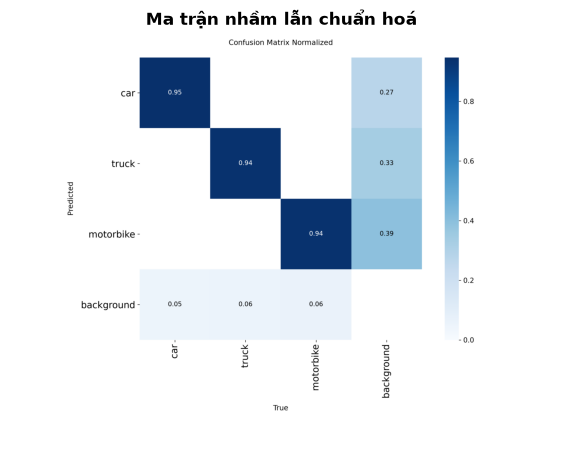

In [4]:
img = plt.imread(RUN / "confusion_matrix_normalized.png")
plt.figure(figsize=(7, 6)); plt.imshow(img); plt.axis("off")
plt.title("Ma trận nhầm lẫn chuẩn hoá", weight="bold"); plt.show()

## 3. Điểm trên tập test có tin được không

Em kiểm tra hai việc. Một là mô hình có học thuộc tập train không, bằng cách so điểm trên train, valid và test.
Hai là ảnh test có bị trùng với ảnh train không, vì nếu trùng thì điểm test sẽ cao hơn thực tế.

In [5]:
sp = J("split_compare")["splits"]
df_sp = pd.DataFrame({k: {m: v[m] for m in ("images", "boxes", "precision", "recall", "mAP50", "mAP50_95")}
                      for k, v in sp.items()}).T
display(df_sp.style.format({"images": "{:.0f}", "boxes": "{:.0f}", "precision": "{:.3f}", "recall": "{:.3f}",
                            "mAP50": "{:.3f}", "mAP50_95": "{:.3f}"}))
print(f"Chenh lech train - test: mAP50 {sp['train']['mAP50'] - sp['test']['mAP50']:+.3f}, "
      f"mAP50-95 {sp['train']['mAP50_95'] - sp['test']['mAP50_95']:+.3f}")

lk = J("leakage_check")
print("Anh trung MD5 (giong het tung byte):", lk["md5_trung"])
print("Trung ten anh goc (cung anh truoc augmentation):", lk["ten_goc_trung"])

,images,boxes,precision,recall,mAP50,mAP50_95
train,1235,5795,0.927,0.955,0.979,0.719
valid,156,708,0.870,0.878,0.935,0.631
test,156,729,0.871,0.867,0.928,0.614


Chenh lech train - test: mAP50 +0.051, mAP50-95 +0.105
Anh trung MD5 (giong het tung byte): {'test_voi_train': 0, 'valid_voi_train': 0, 'test_voi_valid': 0}
Trung ten anh goc (cung anh truoc augmentation): {'test_voi_train': 0, 'valid_voi_train': 0, 'test_voi_valid': 0}


Điểm trên train cao hơn test một chút, tức là có overfitting nhưng nhẹ. Không có ảnh nào trùng giữa các tập. Dù vậy,
nhiều ảnh test được chụp từ cùng camera cố định với ảnh train, nên điểm test chưa cho biết mô hình chạy thế nào với
một camera mới (báo cáo, mục 7.4).

## 4. Vì sao mAP@0.5:0.95 thấp hơn nhiều so với mAP@0.5

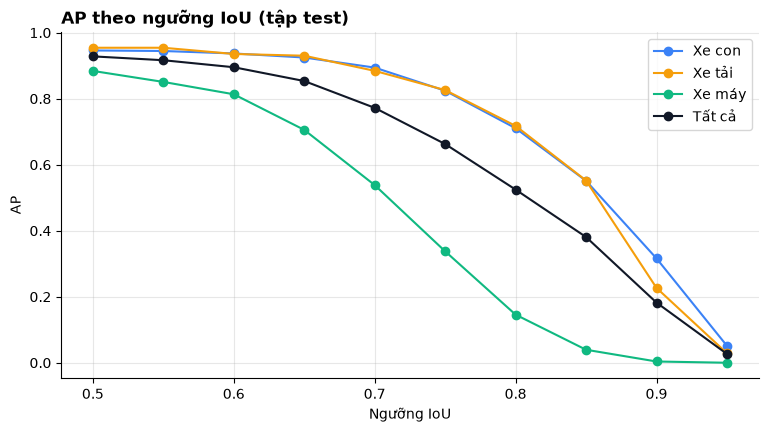

,Xe con,Xe tải,Xe máy,Tất cả
0.50,0.946,0.954,0.884,0.928
0.70,0.894,0.884,0.538,0.772
0.75,0.824,0.826,0.338,0.663
0.80,0.710,0.718,0.146,0.525
0.90,0.316,0.227,0.004,0.182


In [6]:
ma = J("map_analysis")
ap = pd.DataFrame(ma["ap_theo_nguong_iou"])
ap.index = ap.index.astype(float)
ap = ap.rename(columns={**CLASS_LABELS_VI, "tat_ca": "Tất cả"})
ax = ap.plot(marker="o", figsize=(9, 4.5), color=COLORS + ["#111827"])
ax.set_xlabel("Ngưỡng IoU"); ax.set_ylabel("AP"); ax.grid(alpha=0.3)
ax.set_title("AP theo ngưỡng IoU (tập test)", loc="left", weight="bold"); plt.show()
ap.loc[[0.5, 0.7, 0.75, 0.8, 0.9]].round(3)

Ở ngưỡng IoU 0.6, cả ba lớp vẫn có AP trên 0.8. Từ 0.7 trở lên, AP của xe máy tụt nhanh hơn hai lớp kia. Mô hình vẫn
tìm ra xe máy, nhưng box vẽ chưa sát. Box xe máy vốn nhỏ (cạnh trung vị khoảng 38 px, xem notebook 01), nên chỉ lệch
vài pixel là IoU đã giảm nhiều. Lỗi kiểu này ít ảnh hưởng tới việc đếm, vì xe vẫn được phát hiện.

## 5. So sánh với YOLO26n COCO pretrained

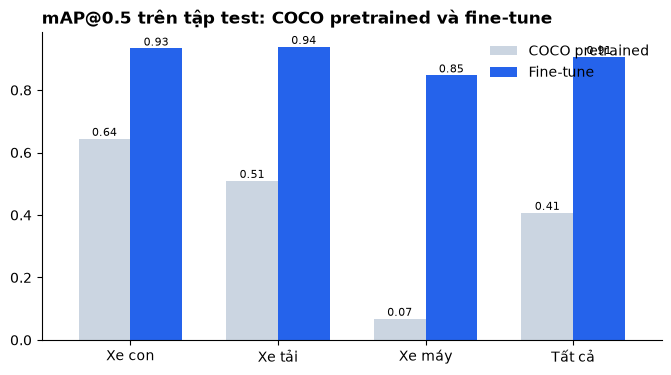

,xe đếm được,số ID,Xe máy,Xe con,Xe tải
vn_giao_thong_ban_ngay.mp4 · coco_pretrained,17,196,14,3,0
vn_giao_thong_ban_ngay.mp4 · fine_tune,24,179,18,4,2
vn_nga_tu_xe_may_o_to.mp4 · coco_pretrained,2,82,1,1,0
vn_nga_tu_xe_may_o_to.mp4 · fine_tune,1,63,0,0,1
vn_hcm_nga_tu_ban_dem.mp4 · coco_pretrained,14,86,10,4,0
vn_hcm_nga_tu_ban_dem.mp4 · fine_tune,16,121,10,4,2
vn_ket_xe_xe_may_o_to.mp4 · coco_pretrained,3,39,0,3,0
vn_ket_xe_xe_may_o_to.mp4 · fine_tune,5,64,0,4,1


In [7]:
bl = J("baseline_compare")
t = bl["tap_test"]
df_bl = pd.DataFrame({
    "COCO pretrained": {CLASS_LABELS_VI[c]: t["coco_pretrained"]["per_class"][c]["mAP50"] for c in CLASS_NAMES},
    "Fine-tune": {CLASS_LABELS_VI[c]: t["fine_tune"]["per_class"][c]["mAP50"] for c in CLASS_NAMES},
})
df_bl.loc["Tất cả"] = [t["coco_pretrained"]["mAP50"], t["fine_tune"]["mAP50"]]
ax = df_bl.plot.bar(rot=0, figsize=(8, 4), color=["#CBD5E1", "#2563EB"], width=0.7)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=8)
ax.set_title("mAP@0.5 trên tập test: COCO pretrained và fine-tune", loc="left", weight="bold")
ax.legend(frameon=False); plt.show()

vid = pd.DataFrame({f"{v} · {m}": {"xe đếm được": r["xe_dem_duoc"], "số ID": r["so_id"],
                                    **{CLASS_LABELS_VI[k]: n for k, n in r["theo_lop"].items()}}
                    for v, mm in bl["video"].items() for m, r in mm.items()}).T.fillna(0).astype(int)
vid

Script đối chứng tính mAP theo cách riêng để hai mô hình được so trong cùng điều kiện, vì vậy số của mô hình fine-tune
ở đây thấp hơn mục 1 một chút. Mô hình COCO gốc gần như không nhận ra xe máy trong ảnh giao thông Việt Nam (mAP@0.5
dưới 0,07), nên phải fine-tune.

## 6. Theo dõi và đếm

In [8]:
tr = J("tracker_compare")
df_tr = pd.DataFrame({(v, k.replace(".yaml", "")): {"xe đếm được": r["xe_dem_duoc"], "số ID": r["so_id"],
                                                    "ID < 10 khung": r["id_ngan_duoi_10_khung"], "FPS": round(r["fps"], 1)}
                      for v, rr in tr["videos"].items() for k, r in rr.items()}).T
print(f"conf = {tr['conf']}, imgsz = {tr['imgsz']}")
df_tr

conf = 0.35, imgsz = 640


xe đếm được  số ID  ID < 10 khung   FPS
vn_nga_tu_xe_may_o_to.mp4  bytetrack          1.0   63.0           39.0  29.2
                           botsort            1.0   59.0           35.0  30.1
vn_ket_xe_xe_may_o_to.mp4  bytetrack          5.0   64.0           33.0  38.6
                           botsort            5.0   63.0           32.0  28.2
vn_giao_thong_ban_ngay.mp4 bytetrack         24.0  179.0           89.0  39.5
                           botsort           24.0  176.0           89.0  30.7
vn_cao_toc_flycam.mp4      bytetrack          7.0   76.0           52.0  42.0
                           botsort            7.0   75.0           52.0  31.4

Ở cả bốn video, ByteTrack và BoT-SORT đếm được cùng số xe, BoT-SORT cấp ít ID hơn một chút. Lý do hệ thống dùng
ByteTrack có trong báo cáo, Tuần 5.

Bảng tiếp theo so số xe hệ thống đếm được với số mình đếm tay trên một video, ở vài mức conf khác nhau.

In [9]:
cnt = J("count_check")
rows = []
for conf, r in cnt["ket_qua"].items():
    for c in CLASS_NAMES:
        rows.append({"conf": conf, "lớp": CLASS_LABELS_VI[c], "hệ thống": r["theo_lop"][c]["he_thong"],
                     "đếm tay": r["theo_lop"][c]["dem_tay"]})
    rows.append({"conf": conf, "lớp": "Tổng", "hệ thống": r["tong"]["he_thong"], "đếm tay": r["tong"]["dem_tay"]})
df_cnt = pd.DataFrame(rows).pivot(index="lớp", columns="conf", values="hệ thống")
df_cnt.insert(0, "đếm tay", pd.DataFrame(rows).groupby("lớp")["đếm tay"].first())
print(f"Video: {cnt['video']} | conf mac dinh: {cnt['conf_mac_dinh']}")
df_cnt.loc[VI + ["Tổng"]]

Video: vn_giao_thong_ban_ngay.mp4 | conf mac dinh: 0.35


conf,đếm tay,0.10,0.20,0.25,0.35
lớp,,,,,
Xe con,8,5,6,6,4
Xe tải,1,4,4,4,2
Xe máy,21,21,20,20,18
Tổng,30,30,30,30,24


Với conf mặc định 0,35, hệ thống đếm thiếu so với đếm tay. Hạ conf xuống thì tổng số xe khớp, nhưng số theo từng loại
vẫn lệch: xe tải bị đếm thừa, xe con bị thiếu. Kết quả này mới dựa trên một video và một lần đếm tay, chưa đủ để chọn
lại ngưỡng conf.

## 7. Tốc độ và độ trễ

In [10]:
bm = J("benchmark")
lat = J("latency")
print("GPU:", bm["gpu"])
display(pd.DataFrame(bm["gpu_rows"]).round(3))
display(pd.DataFrame(bm["cpu_rows"]).round(1))

pt = lat["phan_tich_truc_tiep"]
print(f"Phan tich truc tiep ({pt['video']}, {pt['n']} khung): trung vi {pt['median']:.1f} ms/khung, "
      f"p95 {pt['p95']:.1f} ms, lon nhat {pt['max']:.1f} ms, FPS trung binh {pt['fps_trung_binh']:.1f}")
pd.DataFrame(lat["api"]["csdl_that"]["endpoint"]).T[["median", "p95", "max"]].round(1)

GPU: NVIDIA GeForce RTX 3050 Laptop GPU


,imgsz,mAP50,mAP50_95,fps
0,320,0.880,0.567,44.520
1,480,0.918,0.608,42.520
2,640,0.928,0.614,42.251
3,960,0.922,0.611,40.552
4,1280,0.892,0.566,40.606


,backend,imgsz,fps
0,PyTorch,640,28.0
1,ONNX Runtime,640,23.4


Phan tich truc tiep (vn_giao_thong_ban_ngay.mp4, 579 khung): trung vi 23.4 ms/khung, p95 39.0 ms, lon nhat 41.0 ms, FPS trung binh 38.8


,median,p95,max
/health,2.0,2.3,2.5
/sessions,7.2,7.8,8.7
/stats/summary,7.3,8.1,8.5
/stats/summary?session_id,7.3,7.8,8.6
/stats/timeseries?interval=minute,12.3,13.1,14.6
/events?limit=100,7.8,8.6,9.0


FPS thay đổi theo video và theo từng lần đo, nên báo cáo ghi khoảng 38 đến 48 FPS trên GPU. Bảng cuối là thời gian
phản hồi của từng endpoint API trên CSDL thật, tính bằng mili giây.

## 8. Tổng kết

Cả ba lớp đều có mAP@0.5 trên 0,88 trên tập test. Xe máy yếu nhất ở mAP@0.5:0.95, chủ yếu vì box nhỏ và khó vẽ khít.
Fine-tune là bước cần thiết, vì mô hình COCO gốc gần như bỏ qua xe máy. Pipeline chạy khoảng 38 đến 48 FPS trên GPU
và 28 FPS trên CPU.

Phần đếm vẫn đếm thiếu ở cấu hình mặc định trên video đã đếm tay, cần đếm tay thêm vài video nữa mới kết luận được.
Còn hai điều chưa kiểm chứng: mô hình chạy thế nào với camera mới, và mAP@0.5:0.95 của xe máy thấp là do nhãn hay do
mô hình. Danh sách đầy đủ ở mục 7.4 của báo cáo.